# Research RAG: Chunking, Retrieval and LLM Comparison

Final project of an Information Retrieval course (team project).

The notebook compares two chunking strategies, a local LLM (Flan-T5) against an external API (Llama 3.3 70B via Groq), and a hybrid BM25 + vector retriever, over a corpus of 11 public AI papers and reports. See the README for setup.

In [3]:
# ==========================================
# STEP 1: FRESH INSTALLATION WITH AUTO-RESTART
# ==========================================
import os

# בדיקה אם ההתקנה כבר בוצעה (כדי למנוע לופ של ריסטארטים)
if not os.path.exists('/content/installed.txt'):
    print("⏳ Installing libraries... (This takes ~1 minute)")

    !pip install -U -q \
        langchain==0.1.20 \
        langchain-community==0.0.38 \
        langchain-core==0.1.52 \
        langchain-groq==0.1.3 \
        langchain-huggingface==0.0.3 \
        chromadb==0.5.0 \
        pypdf==4.2.0 \
        pymupdf==1.24.2 \
        sentence-transformers==2.7.0 \
        rank_bm25==0.2.2

    # יצירת קובץ סימון שההתקנה הסתיימה
    with open('/content/installed.txt', 'w') as f:
        f.write('done')

    print("✅ INSTALLATION DONE. Restarting session automatically...")

    # השורה הזו מבצעת ריסטארט אוטומטי ל-Session
    os.kill(os.getpid(), 9)
else:
    print("✅ Libraries already installed. Ready to go!")

✅ Libraries already installed. Ready to go!


✅ GROQ_API_KEY loaded from Colab Secrets.
✅ Libraries loaded.

📂 Loading PDFs from: /content/drive/My Drive/Data
   ✅ Loaded 532 pages.

🧪 EXPERIMENT: Chunking Strategy
   - Small Strategy: 3376 chunks
   - Large Strategy: 1259 chunks

💾 Building Local Vector Stores...


ERROR:chromadb.telemetry.product.posthog:Failed to send telemetry event ClientStartEvent: capture() takes 1 positional argument but 3 were given
ERROR:chromadb.telemetry.product.posthog:Failed to send telemetry event ClientCreateCollectionEvent: capture() takes 1 positional argument but 3 were given
ERROR:chromadb.telemetry.product.posthog:Failed to send telemetry event ClientStartEvent: capture() takes 1 positional argument but 3 were given
ERROR:chromadb.telemetry.product.posthog:Failed to send telemetry event ClientCreateCollectionEvent: capture() takes 1 positional argument but 3 were given


✅ Vector Databases Ready.

🤖 Setting up Models...
   1. Local Model (Flan-T5)...


tokenizer_config.json: 0.00B [00:00, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

...

   2. External API (Groq)...
      ✅ Groq Connected Successfully.
   3. Setting up Hybrid Search...

📊 ================= RESEARCH RESULTS ================= 📊

🔎 Q1: What BLEU score did the Transformer achieve on WMT 2014?


ERROR:chromadb.telemetry.product.posthog:Failed to send telemetry event CollectionQueryEvent: capture() takes 1 positional argument but 3 were given
ERROR:chromadb.telemetry.product.posthog:Failed to send telemetry event CollectionQueryEvent: capture() takes 1 positional argument but 3 were given
Token indices sequence length is longer than the specified maximum sequence length for this model (1311 > 512). Running this sequence through the model will result in indexing errors


🔹 Local (Small): 28.4
🔹 Local (Large): 41.0
🔸 Groq (Llama-3): The Transformer achieved a BLEU score of 28.4 on the WMT 2014 English-to-German translation task. I don't have information about the English-to-French task BLEU score for the Transformer model from the given context, but it is mentioned in Table 2 that the Transformer achieves better BLEU scores than previous state-of-the-art models on the English-to-German and English-to-French newstest2014 tests.
✨ Hybrid Algo: 28.4

🔎 Q2: What backbone architecture does YOLOv8 use?
🔹 Local (Small): YOLO series
🔹 Local (Large): convolutional neural network (CNN)
🔸 Groq (Llama-3): I don't know the specific backbone architecture used by YOLOv8. The provided context does not mention the backbone architecture.
✨ Hybrid Algo: convolutional neural network (CNN)

🔎 Q3: What are the main ethical risks of AI mentioned by UNESCO?
🔹 Local (Small): nn Proportionality and Do No Harm – AI use must be proportional to achieve a given legitimate aim and mu

You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


🔹 Local (Small): We can therefore make use of the chain-of-thought prompts to generate intermediate reasoning steps and reach a correct answer
🔹 Local (Large): a few chain of thought demonstrations are provided as exemplars in prompting. Experiments on three large language models show that chain-of-thought prompting improves performance on a range of arithmetic, commonsense, and symbolic reasoning tasks. The empirical gains can be striking. For instance, prompting a PaLM 540B with just eight chain-of-thought exemplars achieves state-of-the-art accuracy on the GSM8K benchmark of math word problems, surpassing even finetuned GPT-3 with a verifier.
🔸 Groq (Llama-3): Chain-of-Thought prompting improves reasoning by allowing models to decompose multi-step problems into intermediate reasoning steps. This approach enables models to generate step-by-step solutions, working out intermediate results, verifying them, and determining the next steps, ultimately leading to a correct answer. By break

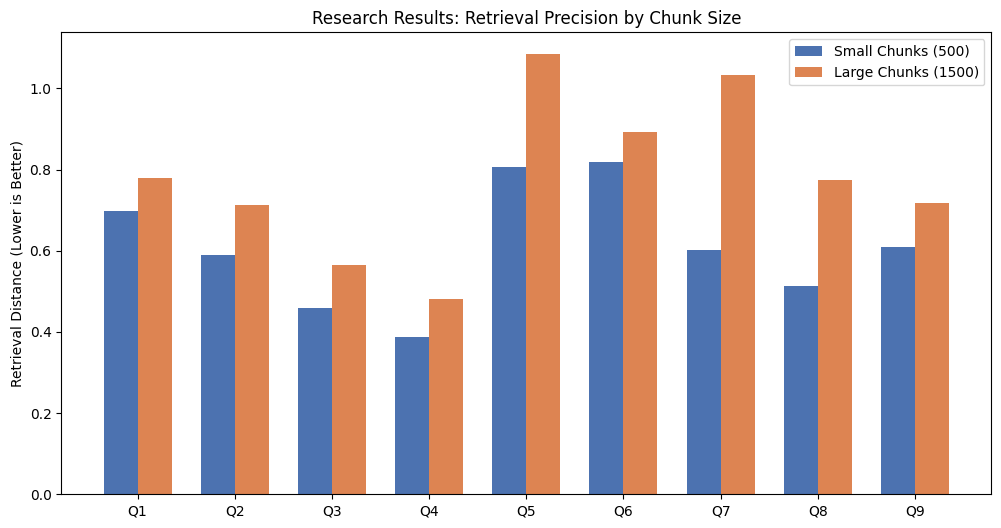


✅ DONE! Experiment Complete.


In [4]:
# ==========================================
# STEP 3: RESEARCH RAG (Fixed Print Statement)
# ==========================================
import os, sys
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive
from google.colab import userdata

# 1. MOUNT DRIVE
if not os.path.ismount('/content/drive'):
    drive.mount('/content/drive')

FOLDER_PATH = '/content/drive/My Drive/Data'

# 2. LOAD GROQ KEY FROM COLAB SECRETS — never hardcode!
# In Colab, click the 🔑 icon on the left sidebar, add a secret named GROQ_API_KEY,
# paste your key as the value, and toggle 'Notebook access' ON.
try:
    GROQ_API_KEY = userdata.get('GROQ_API_KEY')
    assert GROQ_API_KEY, 'Empty key'
    print('✅ GROQ_API_KEY loaded from Colab Secrets.')
except Exception as e:
    GROQ_API_KEY = None
    print(f'⚠️ Could not load GROQ_API_KEY from Colab Secrets: {e}')
    print('   Add it via the 🔑 panel and enable notebook access for this notebook.')

# 3. IMPORTS
try:
    from langchain_community.document_loaders import PyMuPDFLoader
    from langchain_text_splitters import RecursiveCharacterTextSplitter
    from langchain_huggingface import HuggingFaceEmbeddings, HuggingFacePipeline
    from langchain_community.vectorstores import Chroma
    from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, pipeline
    from langchain.chains import RetrievalQA
    from langchain_community.retrievers import BM25Retriever
    from langchain.retrievers import EnsembleRetriever
    from langchain_groq import ChatGroq
    print("✅ Libraries loaded.")
except ImportError:
    print("❌ Libraries missing. Please run Step 1 again.")

# 4. LOAD PDFs
print(f"\n📂 Loading PDFs from: {FOLDER_PATH}")
documents = []
if os.path.exists(FOLDER_PATH):
    pdf_files = [f for f in os.listdir(FOLDER_PATH) if f.endswith('.pdf')]
    for file in pdf_files:
        try:
            loader = PyMuPDFLoader(os.path.join(FOLDER_PATH, file))
            documents.extend(loader.load())
        except: pass
    print(f"   ✅ Loaded {len(documents)} pages.")
else:
    print("❌ Error: Folder not found.")

# 5. CHUNKING
print("\n🧪 EXPERIMENT: Chunking Strategy")
docs_small = RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=50).split_documents(documents)
docs_large = RecursiveCharacterTextSplitter(chunk_size=1500, chunk_overlap=150).split_documents(documents)
print(f"   - Small Strategy: {len(docs_small)} chunks")
print(f"   - Large Strategy: {len(docs_large)} chunks")

# 6. VECTOR DB
print("\n💾 Building Local Vector Stores...")
# Suppress Chroma Noise
import logging
logging.getLogger('chromadb').setLevel(logging.ERROR)

emb_model = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2")
db_small = Chroma.from_documents(docs_small, emb_model, collection_name="db_small_final_v12")
db_large = Chroma.from_documents(docs_large, emb_model, collection_name="db_large_final_v12")
print("✅ Vector Databases Ready.")

# 7. SETUP MODELS
print("\n🤖 Setting up Models...")

# --- A. Local LLM (Flan-T5) ---
print("   1. Local Model (Flan-T5)...")
model_name = "google/flan-t5-large"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSeq2SeqLM.from_pretrained(model_name)
pipe = pipeline("text2text-generation", model=model, tokenizer=tokenizer, max_length=512, temperature=0.1, device=0)
llm_local = HuggingFacePipeline(pipeline=pipe)

# --- B. External API (Groq) ---
print("   2. External API (Groq)...")
try:
    llm_external = ChatGroq(
        temperature=0,
        model_name="llama-3.3-70b-versatile",
        api_key=GROQ_API_KEY
    )
    llm_external.invoke("Test")
    print("      ✅ Groq Connected Successfully.")
except Exception as e:
    print(f"      ⚠️ Groq Error: {e}")
    llm_external = None

# 8. HYBRID SEARCH
print("   3. Setting up Hybrid Search...")
ensemble = EnsembleRetriever(
    retrievers=[BM25Retriever.from_documents(docs_small), db_small.as_retriever(search_kwargs={"k": 3})],
    weights=[0.5, 0.5]
)

# 9. CHAINS
chain_local = RetrievalQA.from_chain_type(llm=llm_local, retriever=db_small.as_retriever(search_kwargs={"k": 3}))
chain_large = RetrievalQA.from_chain_type(llm=llm_local, retriever=db_large.as_retriever(search_kwargs={"k": 3}))
chain_hybrid = RetrievalQA.from_chain_type(llm=llm_local, retriever=ensemble)
chain_ext = None
if llm_external:
    chain_ext = RetrievalQA.from_chain_type(llm=llm_external, retriever=db_small.as_retriever(search_kwargs={"k": 3}))

# 10. RUN EXPERIMENT
questions = [
    "What BLEU score did the Transformer achieve on WMT 2014?",
    "What backbone architecture does YOLOv8 use?",
    "What are the main ethical risks of AI mentioned by UNESCO?",
    "How does Chain-of-Thought prompting improve reasoning?",
    "What is the context window size of Gemini 1.5 Pro?",
    "Which languages does MERLION-TextLLM focus on?",
    "What is the difference between parametric and non-parametric memory?",
    "Explain 'Priming' in prompt engineering.",
    "What are the limitations of Large Language Models?"
]

print("\n📊 ================= RESEARCH RESULTS ================= 📊")
scores_small = []
scores_large = []

for i, q in enumerate(questions):
    print(f"\n🔎 Q{i+1}: {q}")

    # Local Small
    try:
        res = chain_local.invoke(q)['result']
        print(f"🔹 Local (Small): {res}")
        scores_small.append(db_small.similarity_search_with_score(q)[0][1])
    except: scores_small.append(1.5)

    # Local Large
    try:
        res = chain_large.invoke(q)['result']
        print(f"🔹 Local (Large): {res}")
        scores_large.append(db_large.similarity_search_with_score(q)[0][1])
    except: scores_large.append(1.5)

    # Groq (External)
    if chain_ext:
        try:
            res_ext = chain_ext.invoke(q)['result']
            # FIX: Removed .content because res_ext is already a string
            print(f"🔸 Groq (Llama-3): {res_ext}")
        except Exception as e:
            print(f"🔸 Groq: Error ({e})")
    else:
        print("🔸 Groq: [Skipped]")

    # Hybrid
    try:
        print(f"✨ Hybrid Algo: {chain_hybrid.invoke(q)['result']}")
    except: pass

# 11. GENERATE GRAPH
print("\n📈 Generating Research Graph...")
x = np.arange(len(questions))
width = 0.35
fig, ax = plt.subplots(figsize=(12, 6))
rects1 = ax.bar(x - width/2, scores_small, width, label='Small Chunks (500)', color='#4c72b0')
rects2 = ax.bar(x + width/2, scores_large, width, label='Large Chunks (1500)', color='#dd8452')
ax.set_ylabel('Retrieval Distance (Lower is Better)')
ax.set_title('Research Results: Retrieval Precision by Chunk Size')
ax.set_xticks(x)
ax.set_xticklabels([f"Q{i+1}" for i in range(len(questions))])
ax.legend()
plt.show()

print("\n✅ DONE! Experiment Complete.")